## HCP PVS Analysis - EPC Images 

In [ ]:
import numpy as np
from skimage import filters
import nibabel as nib
import matplotlib.pyplot as plt
import os
import yaml
import subprocess
import random
import shutil
from pathlib import Path
import pandas as pd
from skimage.measure import label, regionprops
import csv

In [ ]:
"""
Main Processes:
# HCP PVS Analysis - EPC Images
1. Configuration and Input Data
2. EPC Image Generation
3. Frangi Filtering and PVS Segmentation
4. Visualization of Segmentation Results
5. PVS Mask Post-processing
6. 2D PVS Quantification in the Centrum Semiovale
7. Exporting 2D Quantitative Measurements
8. 3D PVS Quantification
9. Exporting 3D Quantitative Measurements
10. 3D Visualization of PVS Masks

*******************************************Input****************************************************
    T1_acpc_dc_restore_brain_naonlm3d.nii.gz and T2_acpc_dc_restore_brain_naonlm3d.nii.gz
    are the denoised T1w and T2w images used to generate the EPC image.

    Additional input files:
    - wm_mask.nii.gz: White matter mask generated in the T1 pipeline.
    - lateral_ventricle_mask.nii.gz: Lateral ventricle mask used for periventricular exclusion.
    - aparc+aseg.nii.gz: FreeSurfer segmentation image used to generate the lateral ventricle mask.
    - Wardlaw_HCP.csv: Contains subject IDs and radiologist-selected centrum semiovale slice numbers.

*******************************************Processing***********************************************

1) Generating the EPC image:
    input: T1_acpc_dc_restore_brain_naonlm3d.nii.gz and T2_acpc_dc_restore_brain_naonlm3d.nii.gz
    output: EPC.nii.gz
*note: EPC is generated by voxel-wise division of the denoised T1w image by the denoised T2w image.
       The two images must have compatible dimensions and spatial alignment before division.

2) Running QIT (Frangi filter):
    input: EPC.nii.gz and wm_mask.nii.gz
    output: frangi_{alpha}_{beta}.nii.gz and frangi_{alpha}_{beta}.scale.nii.gz

3) Thresholding:
    input: frangi_{alpha}_{beta}.nii.gz
    output: pvs_bin_{alpha}_{beta}_perc{percentile}_th{threshold}.nii.gz

4) Extracting periventricular space:
    - Generating lateral ventricle mask
       input: aparc+aseg.nii.gz
       output: lateral_ventricle_mask.nii.gz

    - Dilating the lateral ventricle mask
       output: dilated_lv_mask_{num_vox_dilation}vox.nii.gz

    - Subtracting the dilated lateral ventricle mask from the PVS binary mask
       output: pvs_bin_perc{percentile}_after_extr_periventr_{num_vox_dilation}vox.nii.gz

5) Visualizing segmentation results:
    - Visualizing the EPC image, Frangi response, Frangi scale, and binary PVS mask.
    - Comparing PVS masks before and after periventricular exclusion.

6) 2D PVS quantification in the centrum semiovale:
    input: Periventricular-excluded PVS binary mask, wm_mask.nii.gz, EPC.nii.gz, and the radiologist-selected slice number from Wardlaw_HCP.csv.
    output: 2D PVS measurements, including PVS count, mean diameter, PVS area, WM area, PVS-to-WM area fraction, PVS-to-WM intensity ratio, and PVS-WM contrast z-score.

7) 3D PVS quantification:
    input: Periventricular-excluded 3D PVS binary mask, wm_mask.nii.gz, and EPC.nii.gz.
    output: 3D PVS measurements, including PVS count, mean diameter, PVS volume, PVS-to-WM volume fraction, PVS-to-WM intensity ratio, and PVS-WM contrast z-score.
*note: 3D connected components are identified using 26-connectivity. The current code retains components with more than 5 voxels.

8) Exporting quantitative measurements:
    output: CSV files containing 2D and 3D PVS measurements.
"""

## Configuration and Input Data

In [ ]:
# Project directory
CURRENT_DIR = Path.cwd()

PROJECT_ROOT = next(
    (p for p in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (p / "notebooks").is_dir()),
    CURRENT_DIR
)

# Project directories
DATA_DIR = PROJECT_ROOT / "data"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
RESULTS_DIR = PROJECT_ROOT / "results"
CONFIG_DIR = PROJECT_ROOT / "config"

# External software
NAONLM3D_EXE = os.getenv("NAONLM3D_EXE") or shutil.which("naonlm3d")
QIT_EXE = os.getenv("QIT_EXE") or shutil.which("qit")

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Outputs directory:", OUTPUTS_DIR)
print("Results directory:", RESULTS_DIR)
print("Config directory:", CONFIG_DIR)
print("NaonLM3D:", NAONLM3D_EXE)
print("QIT:", QIT_EXE)


In [ ]:
# Wardlaw slice information  (will be used in the following stages)
"""
    The slice index in the centrum semiovale is used to calculate
    2D PVS measurements from the segmented PVS mask.

    A neuroradiologist visually assessed PVS in the centrum semiovale
    on T2w and EPC images and recorded the corresponding slice index
    and Wardlaw score in Wardlaw_HCP.csv.
"""

WARDLAW_CSV = DATA_DIR / "Wardlaw_HCP.csv"

if not WARDLAW_CSV.is_file():
    raise FileNotFoundError(
        f"Wardlaw CSV not found: {WARDLAW_CSV}"
    )

wardlaw_df = pd.read_csv(
    WARDLAW_CSV,
    dtype={"subject_id": str}
)

wardlaw_df["subject_id"] = (
    wardlaw_df["subject_id"].str.strip()
)

if wardlaw_df["subject_id"].duplicated().any():
    raise ValueError(
        "Duplicate subject IDs found in Wardlaw_HCP.csv"
    )

slice_map = dict(zip(wardlaw_df["subject_id"], wardlaw_df["slice_num_CS"]))

In [ ]:
def load_subject_ids(subjects_file_path):
    with open(subjects_file_path, 'r') as f:
        sub_ids = [line.strip() for line in f if line.strip()]
    return sub_ids

In [3]:
def generate_config_file(subject_ids, base_data='data', base_outputs='outputs', base_results='results'):
    config = {'paths':{'data':{}, 'outputs':{}, 'results':{}}}
    for s in subject_ids:
        config['paths']['data'][s] = os.path.join(base_data, s, 'T1w')
        config['paths']['outputs'][s] = {
            'outputs_T1' : os.path.join(base_outputs, s, 'outputs_T1'),
            'outputs_T2' : os.path.join(base_outputs, s, 'outputs_T2'),
            'outputs_EPC' : os.path.join(base_outputs, s, 'outputs_EPC'),
        }

        config['paths']['results'][s] = {
            'results_T1' : os.path.join(base_results, s, 'results_T1'),
            'results_T2' : os.path.join(base_results, s, 'results_T2'),
            'results_EPC' : os.path.join(base_results, s, 'results_EPC'),

        }
    return config

In [ ]:
# get the subject ids list 
data_dir = DATA_DIR

if not data_dir.is_dir():
    raise FileNotFoundError(
        f"Data directory not found: {data_dir}"
    )

subject_ids = sorted([
    name for name in os.listdir(data_dir)
    if (data_dir / name).is_dir()
])

print(f"Found {len(subject_ids)} subjects.")


In [ ]:
# generate the config file for all subjects
config_all_sub = generate_config_file(
    subject_ids,
    base_data=str(DATA_DIR),
    base_outputs=str(OUTPUTS_DIR),
    base_results=str(RESULTS_DIR)
)

CONFIG_DIR.mkdir(parents=True, exist_ok=True)

config_path = CONFIG_DIR / "config_all_sub.yml"

with open(config_path, "w") as f:
    yaml.dump(config_all_sub, f, sort_keys=False)

print(
    f"Config saved for {len(subject_ids)} subjects "
    f"to {config_path}"
)

In [ ]:
def get_valid_slices(
    volume_shape,
    axis=2,
    requested_slices=None
):
    """
    Return valid slice indices for a specified image axis.

    Parameters
    ----------
    volume_shape : tuple
        Shape of the 3D image.
    axis : int
        Image axis along which slices are selected.
    requested_slices : list or None
        Optional user-selected slice indices.
        If None, only the middle slice is returned.
    """

    axis_size = volume_shape[axis]

    if axis_size == 0:
        raise ValueError("The selected image axis is empty.")

    middle_slice = axis_size // 2

    if requested_slices is None:
        return [middle_slice]

    valid_slices = [
        int(s) for s in requested_slices
        if isinstance(s, (int, np.integer))
        and 0 <= s < axis_size
    ]

    return sorted(set([middle_slice] + valid_slices))

Saved figure to results/994273/results_T1/combine1.png


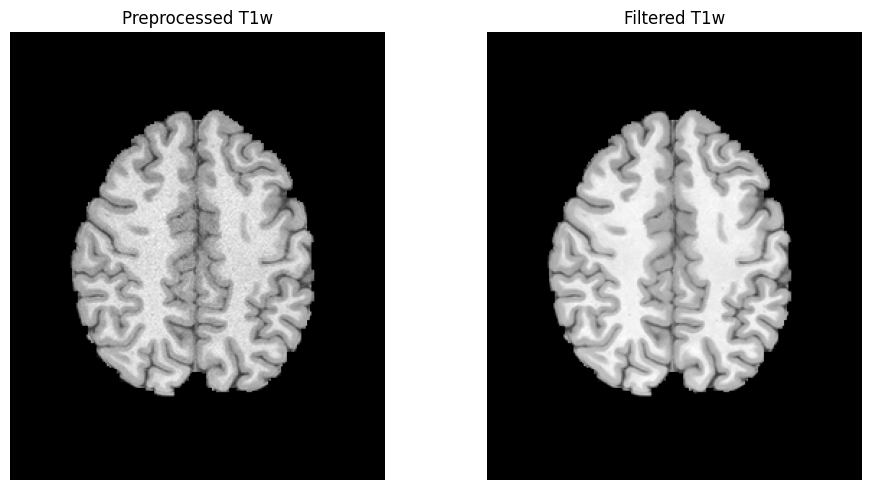

In [ ]:
# Plot denoised input images: Preprocessed T1w and Preprocessed T2w

def plot_t1_denoising_comparison(subject_id, config):
    # Correct way: get the actual string path, not the dict
    results_path = config['paths']['results'][subject_id]['results_T1']
    data_path = config['paths']['data'][subject_id] 

    image_1 = os.path.join(data_path, 'T1w_acpc_dc_restore_brain.nii.gz')
    image_2 = os.path.join(data_path, 'T1_acpc_dc_restore_brain_naonlm3d.nii.gz')
    image_paths = [image_1, image_2]

    titles = ["Preprocessed T1w", "Filtered T1w"]

    # Load images
    images = [nib.load(p).get_fdata() for p in image_paths]

    # Create subplots: 1 row, 2 columns (since you have 2 images)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    for ax, img, title in zip(axes, images, titles):
        mid_slice = get_valid_slices(images[0].shape, axis=2)[0]
        slice_img = np.squeeze(img[:, :, mid_slice])
        ax.imshow(np.rot90(slice_img), cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()

    # Ensure results folder exists
    os.makedirs(results_path, exist_ok=True)

    # Save the figure
    mid_fig_path = os.path.join(results_path, "combine1.png")
    plt.savefig(mid_fig_path, bbox_inches='tight', dpi=300)
    print(f"Saved figure to {mid_fig_path}")

    plt.show()

subject_id = '994273'  # enter the your subject id
plot_t1_denoising_comparison(subject_id, config_all_sub)

Saved figure to results/994273/results_T1/combine1.png


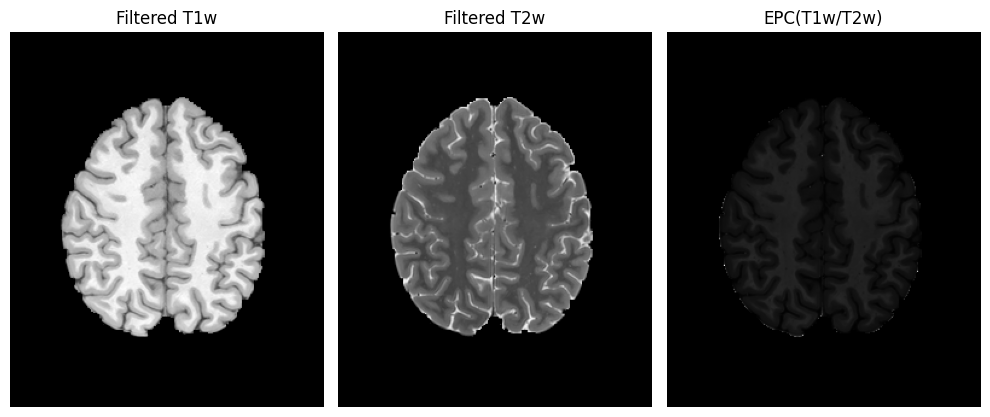

In [ ]:
# Plot denoised input images with generated EPC

def plot_epc_generation_comparison(subject_id, config):
    # Correct way: get the actual string path, not the dict
    results_path = config['paths']['results'][subject_id]['results_T1']
    data_path = config['paths']['data'][subject_id] 

    image_1 = os.path.join(data_path, 'T1_acpc_dc_restore_brain_naonlm3d.nii.gz')
    image_2 = os.path.join(data_path, 'T2_acpc_dc_restore_brain_naonlm3d.nii.gz')
    image_3 = os.path.join(data_path, 'EPC.nii.gz')
    image_paths = [image_1, image_2, image_3]

    titles = ["Filtered T1w", "Filtered T2w", "EPC(T1w/T2w)"]

    # Load images
    images = [nib.load(p).get_fdata() for p in image_paths]

    # Create subplots: 1 row, 2 columns (since you have 2 images)
    fig, axes = plt.subplots(1, 3, figsize=(10, 5))

    for ax, img, title in zip(axes, images, titles):
        mid_slice = get_valid_slices(images[0].shape, axis=2)[0]
        slice_img = np.squeeze(img[:, :, mid_slice])
        ax.imshow(np.rot90(slice_img), cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()

    # Ensure results folder exists
    os.makedirs(results_path, exist_ok=True)

    # Save the figure
    mid_fig_path = os.path.join(results_path, "combine1.png")
    plt.savefig(mid_fig_path, bbox_inches='tight', dpi=300)
    print(f"Saved figure to {mid_fig_path}")

    plt.show()

EXAMPLE_SUBJECT_ID = "994273"   # enter the example subject id
plot_epc_generation_comparison(EXAMPLE_SUBJECT_ID, config_all_sub)

## EPC Image Generation

In [ ]:
def create_EPC(subject_id, config):

    data_path = config['paths']['data'][subject_id]

    # File paths
    t1_path = os.path.join(data_path, 'T1_acpc_dc_restore_brain_naonlm3d.nii.gz')
    t2_path = os.path.join(data_path, 'T2_acpc_dc_restore_brain_naonlm3d.nii.gz')
    epc_path = os.path.join(data_path, 'EPC.nii.gz')

    # Load images
    t1_img = nib.load(t1_path)
    t2_img = nib.load(t2_path)

    t1_data = t1_img.get_fdata()
    t2_data = t2_img.get_fdata()

    # Check the shape and spatial alignment of T1w and T2w images before voxel-wise division to generate EPC.
        
    if t1_img.shape != t2_img.shape:
        raise ValueError("T1 and T2 images have different shapes.")

    if not np.allclose(t1_img.affine, t2_img.affine, atol=1e-5):
        raise ValueError("T1 and T2 images are not spatially aligned.")

    print(f't1_data shape: {t1_data.shape}')
    print(f't2_data shape: {t2_data.shape}')

    print(np.min(t1_data), np.max(t1_data))
    print(np.min(t2_data), np.max(t2_data))

    print("T1 stats:")
    print(" min:", np.min(t1_data), " max:", np.max(t1_data), " 99%:", np.percentile(t1_data, 99))

    print("T2 stats:")
    print(" min:", np.min(t2_data), " max:", np.max(t2_data), " 99%:", np.percentile(t2_data, 99))


    # Avoid division by zero
    with np.errstate(divide='ignore', invalid='ignore'):
        epc_data = np.divide(t1_data, t2_data)
        epc_data[np.isnan(epc_data)] = 0
        epc_data[np.isinf(epc_data)] = 0

    
    # Save EPC image
    epc_img = nib.Nifti1Image(epc_data, affine=t1_img.affine)
    nib.save(epc_img, epc_path)

    print(f"EPC image saved for {subject_id} at: {epc_path}")

    return epc_path

## Frangi Filtering and PVS Segmentation

In [ ]:
# Note:
# Before Frangi filtering, ensure that the input MRI and WM mask have matching dimensions and spatial alignment.

In [ ]:
# QIT is a tool for running Frangi filter to segment PVS

def run_qit(input_image_path, wm_mask_path, output_image_path):

    if not QIT_EXE:
        raise FileNotFoundError(
          "QIT was not found. Set the QIT_EXE environment variable."
    )

    qit_executable = QIT_EXE


    alpha = "0.1"
    beta = "0.9"
    
    os.makedirs(output_image_path, exist_ok=True)

    frangi_output_path = f"{output_image_path}/frangi_{alpha}_{beta}.nii.gz"
    frangi_scale_output_path = f"{output_image_path}/frangi_{alpha}_{beta}.scale.nii.gz"


    cmd = [
        qit_executable, "VolumeFilterFrangi",
        "--input", input_image_path,
        "--support", "3",
        "--num", "0",
        "--low", "0.5",
        "--high", "1",
        "--alpha", alpha,
        "--beta", beta,
        "--mask", wm_mask_path,
        "--dark",
        "--output", frangi_output_path,
        "--outputScale", frangi_scale_output_path
    ]


    subprocess.run(cmd, check=True)

    if not Path(frangi_output_path).is_file():
        raise RuntimeError(
            f"QIT did not create the expected output: {frangi_output_path}"
        )

    if not Path(frangi_scale_output_path).is_file():
        raise RuntimeError(
            f"QIT did not create the expected output: {frangi_scale_output_path}"
        )

    print("QIT command executed successfully.")

    return frangi_output_path, frangi_scale_output_path, alpha, beta   


In [ ]:
# Threshold the output of the frangi filter to create a binary mask

def threshold_pvs(denoised_data_path, output_path, alpha=0.1, beta=0.9, percentile=90):

    frangi_path = os.path.join(output_path, f'frangi_{alpha}_{beta}.nii.gz')

    if not os.path.exists(frangi_path):
        raise FileNotFoundError(f"Frangi file not found: {frangi_path}")

    frangi_image = nib.load(frangi_path)
    frangi_data = frangi_image.get_fdata()

    if np.sum(frangi_data > 0) == 0:
        raise ValueError("Frangi image has no non-zero voxels.")

    denoised_image = nib.load(denoised_data_path)

    threshold = np.percentile(frangi_data[frangi_data > 0], percentile)

    pvs_bin = (frangi_data > threshold).astype(np.float32)

    # save the pvs_bin
    pvs_bin_path = f'{output_path}/pvs_bin_{alpha}_{beta}_perc{percentile}_th{np.round(threshold, 3)}.nii.gz'
    nib.save(nib.Nifti1Image(pvs_bin, denoised_image.affine), pvs_bin_path)

    return pvs_bin, threshold, pvs_bin_path

In [ ]:
def step3_run_qit(subject_id, config, modality='EPC'):

    data_path = config['paths']['data'][subject_id]

    outputs_key = f'outputs_{modality}'
    output_path = config['paths']['outputs'][subject_id][outputs_key]
    
    denoised_path = os.path.join(data_path, f'{modality}.nii.gz')

    # White matter mask is generated through running 01_HCP_T1_PVS_Pipeline.ipynb and saved in the data_path
    wm_mask_path = os.path.join(data_path, 'wm_mask.nii.gz')

    frangi_path, scale_path, alpha, beta = run_qit(denoised_path, wm_mask_path, output_path)

    print(f"[Step 3] QIT run for {subject_id}")
    
    return frangi_path, scale_path, alpha, beta

In [ ]:
for subject_id in subject_ids:
    try:
        create_EPC(subject_id, config_all_sub)
    except Exception as e:
        print(f"Error in Step 1 for subject {subject_id}: {e}")

In [ ]:
for subject_id in subject_ids:
    try:
        step3_run_qit(subject_id, config_all_sub, modality='EPC')
    except Exception as e:
        print(f"Error in Step 3 for subject {subject_id}: {e}")

In [13]:
def step4_threshold(subject_id, config, alpha=0.1, beta=0.9, modality='EPC'):

    data_path = config['paths']['data'][subject_id]

    outputs_key = f'outputs_{modality}'
    output_path = config['paths']['outputs'][subject_id][outputs_key]

    denoised_path = os.path.join(data_path, f'{modality}.nii.gz')


    pvs_bin, threshold, pvs_bin_path = threshold_pvs(denoised_path, output_path, alpha, beta, percentile=90)
    
    print(f"Saved PVS binary mask to: {pvs_bin_path}")
    print(f"[Step 4] Thresholding done for {subject_id}")

    return pvs_bin


In [ ]:
for subject_id in subject_ids:
    try:
        step4_threshold(subject_id, config_all_sub, modality='EPC')
    except Exception as e:
        print(f"Error in Step 4 for subject {subject_id}: {e}")

## Visualization of Segmentation Results

In [ ]:
def plot_random_subject_result(config, modality='EPC', percentile=90):

    subject_id = random.choice(list(config['paths']['data'].keys()))
    print(f"Selected subject: {subject_id}")

    data_path = config['paths']['data'][subject_id]
    outputs_path = config['paths']['outputs'][subject_id][f'outputs_{modality}']
    results_path = config['paths']['results'][subject_id][f'results_{modality}']

    os.makedirs(results_path, exist_ok=True)  # Make sure result dir exists

    alpha = 0.1
    beta = 0.9

    # Load images
    denoised_epc_path = os.path.join(data_path, 'EPC.nii.gz')
    frangi_path = os.path.join(outputs_path, f"frangi_{alpha}_{beta}.nii.gz")
    frangi_scale_path = os.path.join(outputs_path, f"frangi_{alpha}_{beta}.scale.nii.gz")
        
    pvs_bin_path = None
    for fname in os.listdir(outputs_path):
        if fname.startswith("pvs_bin_") and f"perc{percentile}" in fname:   #?????????????????doubt
            pvs_bin_path = os.path.join(outputs_path, fname)
            break

    if pvs_bin_path is None:
        raise FileNotFoundError(f"No thresholded PVS image found with perc{percentile} in {outputs_path}.")

    threshold = fname.split("th")[-1].replace(".nii.gz", "")

    denoised_data = nib.load(denoised_epc_path).get_fdata()
    frangi_data = nib.load(frangi_path).get_fdata()
    frangi_scale_data = nib.load(frangi_scale_path).get_fdata()
    pvs_bin = nib.load(pvs_bin_path).get_fdata()

    middle_slice = denoised_data.shape[2] // 2
    slices = get_valid_slices(denoised_data.shape, axis=2, requested_slices=[142, 147, 161, 132, 169, 176])
    print("Slices selected for visualization:", slices)

    # plot the histogram 
    plt.figure(figsize=(15, 5))
    plt.subplot(121)
    plt.hist(frangi_data.flatten(), bins=100, log=True)
    plt.xlabel("Frangi Value")
    plt.ylabel("Frequency (log scale)")
    plt.title('Frangi Histogram')

    plt.subplot(122)
    plt.hist(frangi_scale_data.flatten(), bins=100, log=True)
    plt.xlabel("Frangi Scale Value")
    plt.ylabel("Frequency (log scale)")
    plt.title('Frangi Scale Histogram')

    hist_path = os.path.join(results_path, f"img_hist_{alpha}_{beta}_perc{percentile}.png")
    # plt.savefig(hist_path, bbox_inches='tight', dpi=300)
    plt.show()

    # plot the Denoised, Frangi, Frangi_scale, PVS Bin mid slice
    fig, axs = plt.subplots(1, 4, figsize=(15, 5))
    titles = ['EPC', 'Frangi Scale', 'Frangi', 'PVS Bin']
    images = [denoised_data, frangi_scale_data, frangi_data, pvs_bin]

    for i, ax in enumerate(axs):
        cmap = 'gray' if i == 0 else 'hot'
        ax.imshow(np.rot90(images[i][:, :, middle_slice], k=1), cmap=cmap)
        ax.set_title(f"{titles[i]} (Mid)")
        ax.axis('off')

    plt.tight_layout()
    mid_fig_path = os.path.join(results_path, f"overview_mid_slice_{alpha}_{beta}_perc{percentile}.png")
    # plt.savefig(mid_fig_path, bbox_inches='tight', dpi=300)
    plt.show()

    # Overlays for each slice
    for slc in slices:
        fig, axs = plt.subplots(1, 4, figsize=(15, 5))

        # Frangi Axial
        axs[0].imshow(np.rot90(denoised_data[:, :, slc], k=1), cmap='gray')
        axs[0].imshow(np.rot90(frangi_data[:, :, slc], k=1), cmap='hot', alpha=0.5)
        axs[0].set_title(f'Frangi Axial (Slice {slc})')
        axs[0].axis('off')

        # PVS Bin Axial (Red)
        axs[1].imshow(np.rot90(denoised_data[:, :, slc], k=1), cmap='gray')
        axs[1].imshow(np.rot90(pvs_bin[:, :, slc], k=1), cmap='hot', alpha=0.5)
        axs[1].set_title(f'PVS Bin Axial (Slice {slc})')
        axs[1].axis('off')

        # PVS Bin Coronal (Red)
        axs[2].imshow(np.rot90(denoised_data[:, slc, :], k=1), cmap='gray')
        axs[2].imshow(np.rot90(pvs_bin[:, slc, :], k=1), cmap='hot', alpha=0.5)
        axs[2].set_title(f'PVS Bin Coronal (Slice {slc})')
        axs[2].axis('off')

        # PVS Bin Sagittal (Red)
        axs[3].imshow(np.rot90(denoised_data[slc, :, :], k=1), cmap='gray')
        axs[3].imshow(np.rot90(pvs_bin[slc, :, :], k=1), cmap='hot', alpha=0.5)
        axs[3].set_title(f'PVS Bin Sagittal (Slice {slc})')
        axs[3].axis('off')

        plt.tight_layout()
        overlay_path = os.path.join(results_path, f"overlay_slice_{slc}_{alpha}_{beta}_perc{percentile}.png")
        # plt.savefig(overlay_path, bbox_inches='tight', dpi=300)
        plt.show()


Selected subject: 994273


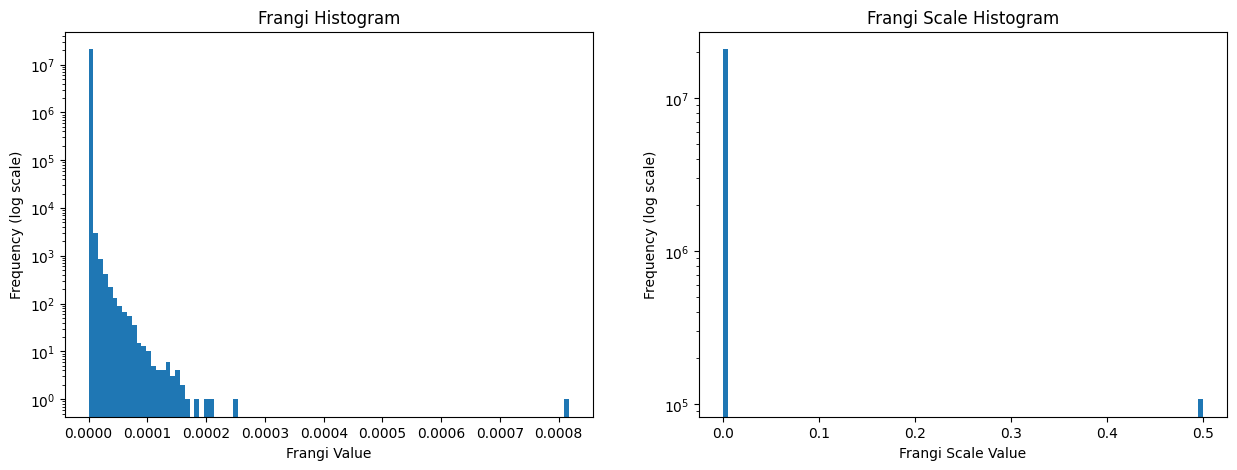

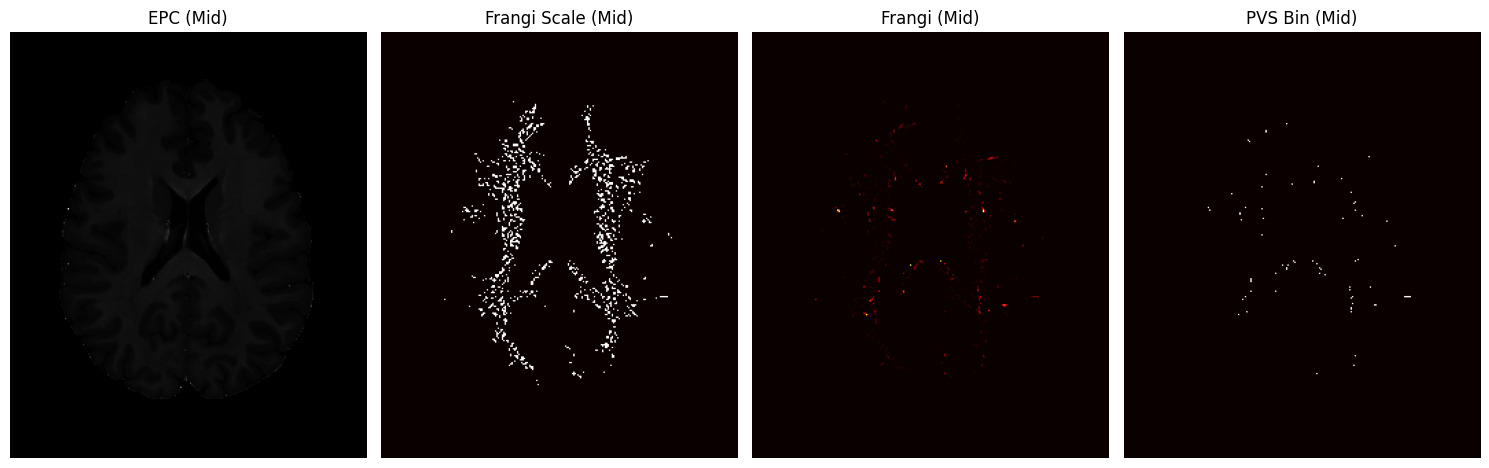

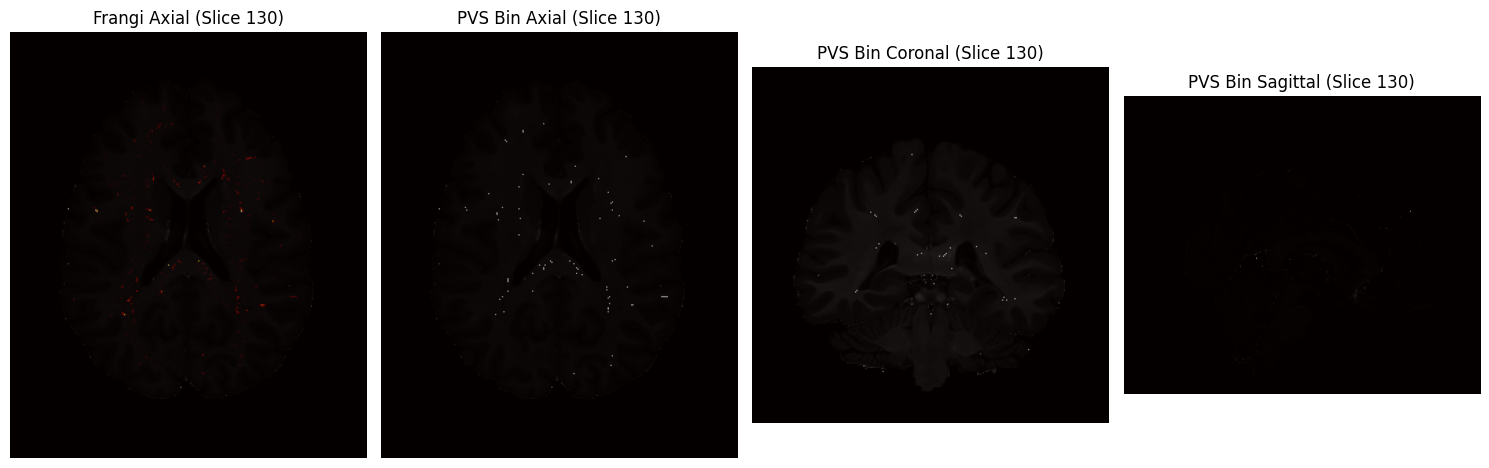

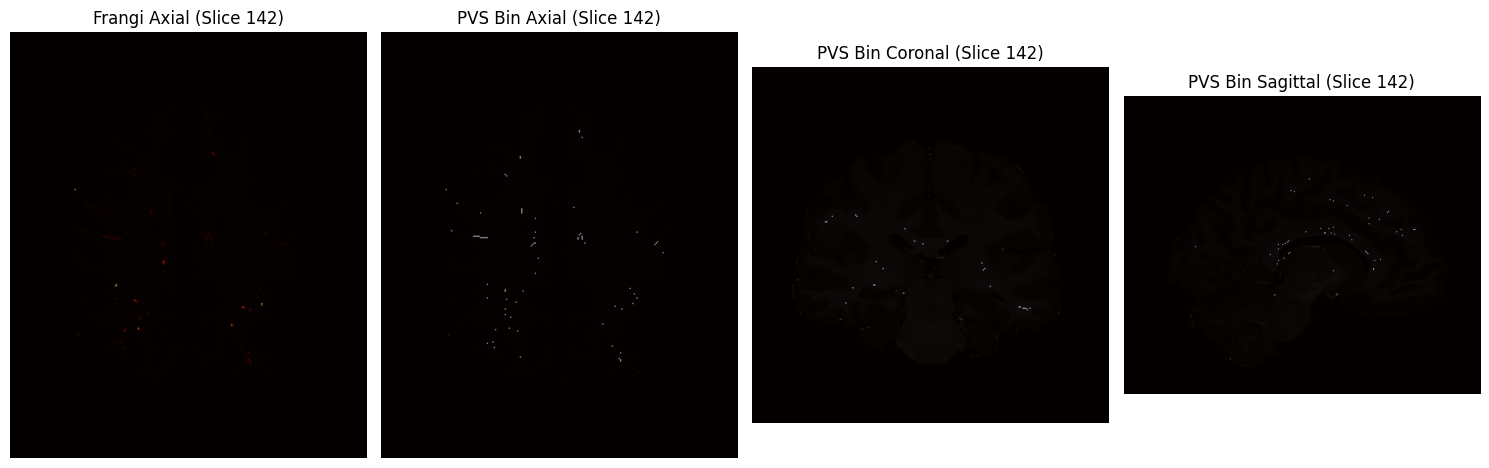

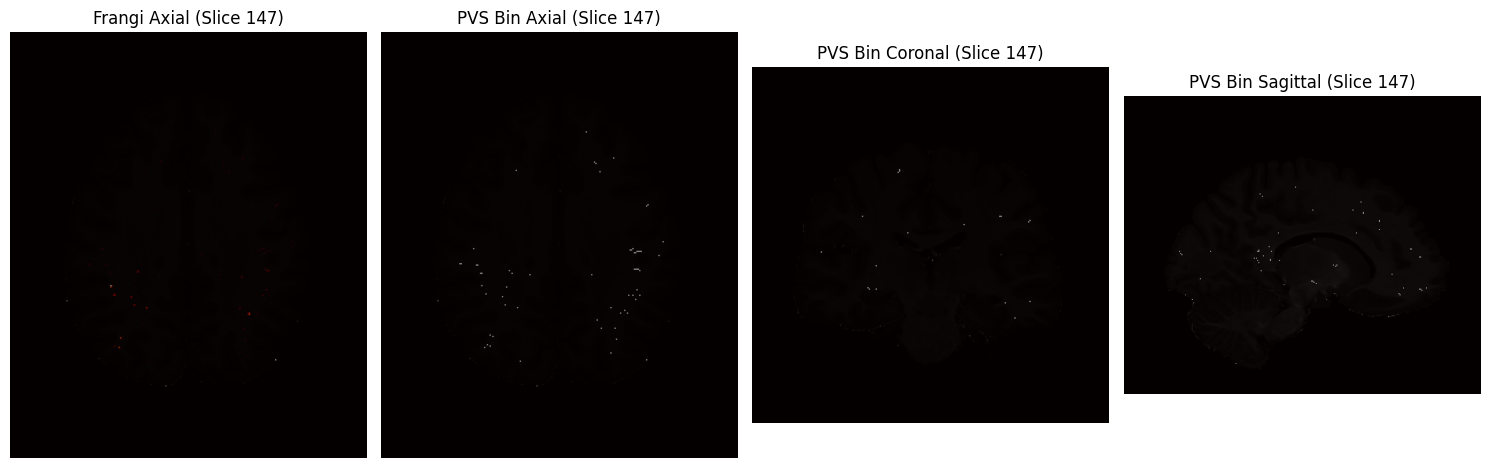

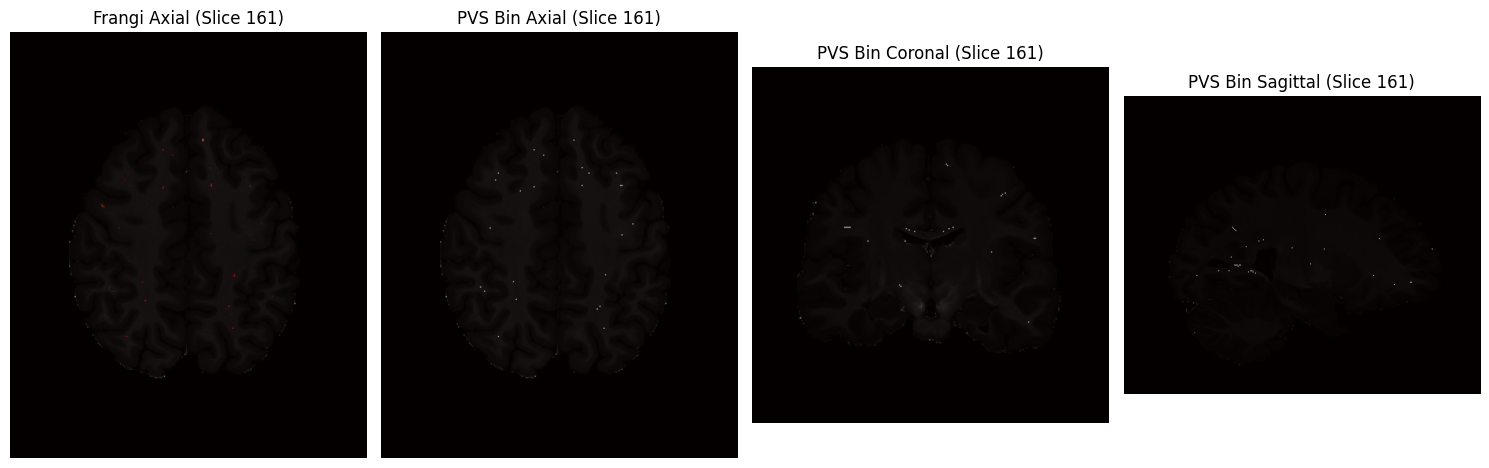

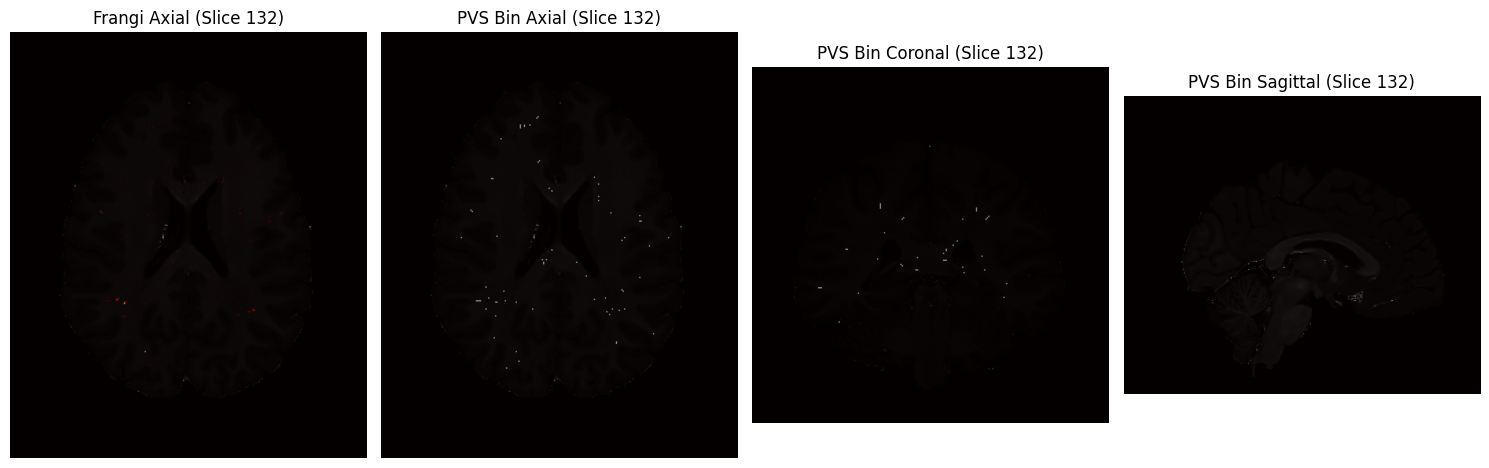

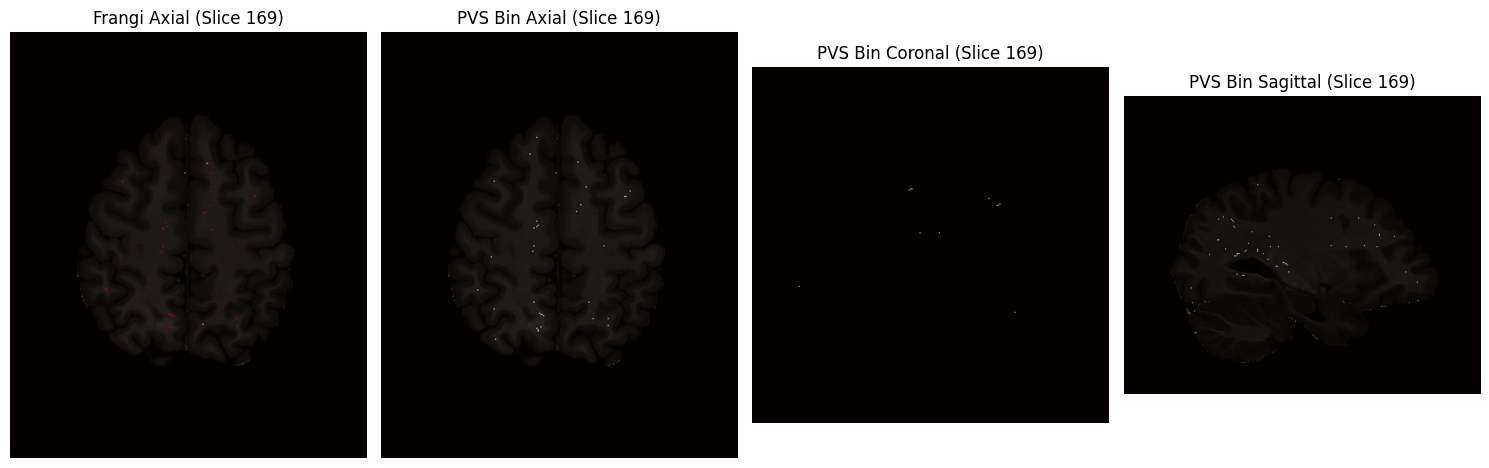

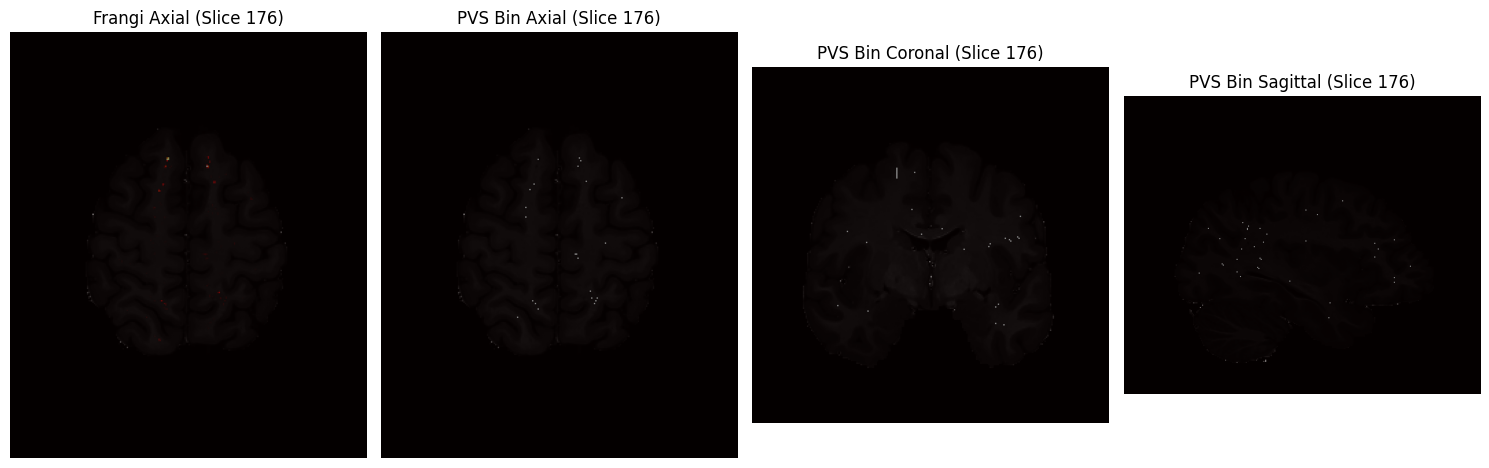

In [7]:
plot_random_subject_result(config_all_sub, modality='EPC', percentile=90)

## PVS Mask Post-processing: Extract the Periventricular mask


In [ ]:
def extract_periventricular_space(subject_id, config, modality='EPC', percentile=90):

    data_path = config['paths']['data'][subject_id]
    outputs_key = f'outputs_{modality}'
    outputs_path = config['paths']['outputs'][subject_id][outputs_key]
    results_key = f'results_{modality}'
    results_path = config['paths']['results'][subject_id][results_key]

    denoised_epc_path = os.path.join(data_path, 'EPC.nii.gz')
    denoised_epc_data = nib.load(denoised_epc_path).get_fdata()

    # Load the lateral ventricle mask
    lv_mask_path = os.path.join(data_path, 'lateral_ventricle_mask.nii.gz')

    # dilate the lateral_ventricle_mask
    num_vox_dilation = 3
    dilated_lv_mask_path = os.path.join(outputs_path, f'dilated_lv_mask_{num_vox_dilation}vox.nii.gz')

    cmd = [
    'mri_binarize',
    '--i', lv_mask_path,
    '--dilate', str(num_vox_dilation),
    '--min', '0.5',
    '--o', dilated_lv_mask_path
    ]
    subprocess.run(cmd, check=True)

    # find threshold  value and pvs_bin_path
    pvs_bin_path = None
    for fname in os.listdir(outputs_path):
        # Match strictly only original thresholded PVS files
        if fname.startswith(f"pvs_bin_0.1_0.9_perc{percentile}_th") and fname.endswith(".nii.gz"):
            threshold = fname.split("th")[-1].replace(".nii.gz", "")
            pvs_bin_path = os.path.join(outputs_path, fname)
            print(f"Using threshold {threshold} for subject {subject_id}, modality {modality}")
            break

    if pvs_bin_path is None:
        raise FileNotFoundError(f"No original thresholded PVS image found in {outputs_path} for modality {modality}")


    threshold = fname.split("th")[-1].replace(".nii.gz", "")  # not necessary

  	# Remove PVS candidates within the dilated lateral ventricle mask
    
    pvs_bin_data = nib.load(pvs_bin_path).get_fdata()

    pvs_after_ext_peri_path = f"{outputs_path}/pvs_bin_perc{percentile}_after_extr_periventr_{num_vox_dilation}vox.nii.gz"

    subprocess.run(["fslmaths", pvs_bin_path, "-sub", dilated_lv_mask_path, "-thr", "0", pvs_after_ext_peri_path], check=True)

    #plot the results:
    pvs_after_ext_peri_data = nib.load(pvs_after_ext_peri_path).get_fdata()

    os.makedirs(results_path, exist_ok=True)

    # 2D Overlays
    slice_idx = get_valid_slices(denoised_epc_data.shape, axis=2, requested_slices=[132])[0]
    plt.figure(figsize=(15, 5))
    plt.subplot(121)
    plt.imshow(np.rot90(denoised_epc_data[:, :, slice_idx], k=1), cmap='gray')
    plt.imshow(np.rot90(pvs_bin_data[:, :, slice_idx], k=1), cmap='hot', alpha=0.5)
    plt.title('PVS Before Extraction')

    plt.subplot(122)
    plt.imshow(np.rot90(denoised_epc_data[:, :, slice_idx], k=1), cmap='gray')
    plt.imshow(np.rot90(pvs_after_ext_peri_data[:, :, slice_idx], k=1), cmap='hot', alpha=0.5)
    plt.title('PVS After Periventricular Extraction')

    plt.savefig(f"{results_path}/pvs_extraction_2d.png", bbox_inches='tight', dpi=300)
    plt.close()

    return pvs_after_ext_peri_path



In [ ]:
for subject_id in subject_ids:
    try:
        extract_periventricular_space(subject_id, config_all_sub, modality='EPC', percentile=90)
    except Exception as e:
        print(f"Error in extracting periventricular space for subject {subject_id}: {e}")

## 2D PVS Quantification in the Centrum Semiovale

In [ ]:
def compute_2d_pvs_metrics(subject_id, config, slice_map, modality='EPC', percentile=90):

    # Retrieve the radiologist-selected slice in the centrum semiovale
    subject_id = str(subject_id)
    
    if subject_id not in slice_map:
        raise KeyError(
            f"Subject {subject_id} not found in Wardlaw_HCP.csv"
        )

    slice_index = int(slice_map[subject_id])

    # === Load data ===
    data_path = config['paths']['data'][subject_id]
    outputs_path = config['paths']['outputs'][subject_id][f'outputs_{modality}']

    pvs_path = os.path.join(outputs_path, f"pvs_bin_perc{percentile}_after_extr_periventr_3vox.nii.gz")
    wm_mask_path = os.path.join(data_path, 'wm_mask.nii.gz')
    modality_path = os.path.join(data_path, f'{modality}.nii.gz')

    pvs_img = nib.load(pvs_path)
    wm_img = nib.load(wm_mask_path)
    modality_img = nib.load(modality_path)

    pvs_data = pvs_img.get_fdata()
    wm_data = wm_img.get_fdata()
    modality_data = modality_img.get_fdata()
    affine = pvs_img.affine

    # === Extract slices ===
    pvs_slice = pvs_data[:, :, slice_index]
    wm_slice = wm_data[:, :, slice_index]
    modality_slice = modality_data[:, :, slice_index]

    # === Calculate voxel area in mm ===
    voxel_size_x = np.linalg.norm(affine[:3, 0])
    voxel_size_y = np.linalg.norm(affine[:3, 1])
    voxel_area_mm2 = voxel_size_x * voxel_size_y

    # === Label and extract PVS regions ===

    # The minimum component-size threshold is applied only to PVS count and mean diameter calculations.
    # PVS area and intensity-based measurements are calculated using all foreground voxels in the original binary PVS mask.

    labeled = label(pvs_slice, connectivity=1)
    regions = regionprops(labeled)

    count = 0
    diameters_vox = []
    diameters_mm = []
    min_vox_EPC = 2   # Define it according to your PVS results

    for r in regions:
        if r.area >= min_vox_EPC:
            count += 1
            # Equivalent circular diameter
            d_vox = ((4 * r.area) / np.pi) ** 0.5
            area_mm2 = r.area * voxel_area_mm2
            d_mm = ((4 * area_mm2) / np.pi) ** 0.5

            diameters_vox.append(d_vox)
            diameters_mm.append(d_mm)

    mean_diameter_vox = np.mean(diameters_vox) if diameters_vox else 0
    mean_diameter_mm = np.mean(diameters_mm) if diameters_mm else 0

    # === Area-based metrics ===
    pvs_voxels = np.sum(pvs_slice > 0)
    wm_voxels = np.sum(wm_slice > 0)
    pvs_area = pvs_voxels * voxel_area_mm2
    wm_area = wm_voxels * voxel_area_mm2

    if wm_area <= 0:
        raise ValueError(f"[{subject_id}] WM area is zero! Check mask alignment.")

    pvsvf_2d = pvs_area / wm_area

    # === Intensity-based metrics ===
    mean_pvs_intensity = np.mean(modality_slice[pvs_slice > 0]) if pvs_voxels > 0 else 0
    mean_wm_intensity = np.mean(modality_slice[wm_slice > 0]) if wm_voxels > 0 else 0
    pvs_to_wm_ratio = mean_pvs_intensity / mean_wm_intensity if mean_wm_intensity > 0 else 0

    # === Z-scored contrast ===
    wm_values = modality_slice[wm_slice > 0]
    wm_mean = np.mean(wm_values)
    wm_std = np.std(wm_values)
    modality_z = (modality_slice - wm_mean) / wm_std if wm_std > 0 else np.zeros_like(modality_slice)
    pvs_to_wm_ratio_z = np.mean(modality_z[pvs_slice > 0]) if pvs_voxels > 0 else 0

    # === Print results ===
    print(f"Subject: {subject_id}, Slice: {slice_index}")
    print(f"PVS count: {count}")
    print(f"Mean diameter: {mean_diameter_vox:.2f} vox | {mean_diameter_mm:.2f} mm")
    print(f"PVS area: {pvs_area:.2f} mm and WM area: {wm_area:.2f} mm")
    print(f"PVSvF (2D): {pvsvf_2d:.6f}")
    print(f"Intensity ratio: {pvs_to_wm_ratio:.3f}")
    print(f"Z-score contrast: {pvs_to_wm_ratio_z:.3f}")

    # === Return all metrics ===
    return {
        "subject_id": subject_id,
        "slice_index": slice_index,
        "pvs_count": count,
        "mean_diameter_vox": mean_diameter_vox,
        "mean_diameter_mm": mean_diameter_mm,
        "pvs_area_mm2": pvs_area,
        "wm_area_mm2": wm_area,
        "pvsvf_2d": pvsvf_2d,
        "pvs_to_wm_ratio": pvs_to_wm_ratio,
        "pvs_to_wm_ratio_z": pvs_to_wm_ratio_z
    }


## Exporting 2D Quantitative Measurements

In [ ]:
# File path
outputs_csv_path = OUTPUTS_DIR / "pvs_2D_metrics_perc90.csv"

# Ensure the outputs directory exists
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

# Debugging: print the current working directory
print(f"Current working directory: {os.getcwd()}")
print(f"Output CSV path: {outputs_csv_path}")

# Check if file exists, read existing rows or start fresh
if os.path.exists(outputs_csv_path):
    with open(outputs_csv_path, 'r', newline='') as csvfile:
        reader = csv.DictReader(csvfile)
        rows = list(reader)
    print("Loaded existing CSV data.")
else:
    rows = []
    print("No CSV found - starting new results table.")

fieldnames = [
    'subject_id', 
    'pvs_count_EPC', 'mean_diameter_vox_EPC', 'mean_diameter_mm_EPC', 
    'pvs_area_mm2_EPC', 
    'pvsvf_wm_EPC', 
    'pvs_to_wm_ratio_EPC', 
    'pvs_wm_contrast_z_EPC',
    'pvs_count_T2', 'mean_diameter_vox_T2', 'mean_diameter_mm_T2', 
    'pvs_area_mm2_T2', 
    'pvsvf_wm_T2', 
    'pvs_to_wm_ratio_T2', 
    'pvs_wm_contrast_z_T2'
]


for subject_id in subject_ids:
    try:
        metrics = compute_2d_pvs_metrics(subject_id, config_all_sub, slice_map=slice_map, modality='EPC', percentile=90)

        # Check if subject already exists
        subject_row = None
        for row in rows:
            if row['subject_id'] == subject_id:
                subject_row = row
                break

        if subject_row is None:
            subject_row = {'subject_id': subject_id}
            rows.append(subject_row)

        # Update EPC fields
        subject_row['pvs_count_EPC'] = metrics['pvs_count']
        subject_row['mean_diameter_vox_EPC'] = metrics['mean_diameter_vox']
        subject_row['mean_diameter_mm_EPC'] = metrics['mean_diameter_mm']
        subject_row['pvs_area_mm2_EPC'] = metrics['pvs_area_mm2']
        subject_row['pvsvf_wm_EPC'] = metrics['pvsvf_2d']
        subject_row['pvs_to_wm_ratio_EPC'] = metrics['pvs_to_wm_ratio']
        subject_row['pvs_wm_contrast_z_EPC'] = metrics['pvs_to_wm_ratio_z']

        print(f"Updated EPC metrics for {subject_id}")


    except Exception as e:
        print(f"Error processing {subject_id}: {e}")


# Write everything back - all columns preserved!
with open(outputs_csv_path, 'w', newline='') as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

print("EPC metrics updated safely - EPC results untouched.")


## 3D PVS Quantification

In [ ]:
# Note:
# The HCP-preprocessed T1w, T2w, and aseg+aparc images are provided in native space, with dimensions corresponding to their respective raw T1w and T2w images.
# Before Quantitative analysis, ensure that the PVS mask, WM mask, and corresponding intensity image have matching dimensions and spatial alignment.

In [ ]:
# Calculate the equivalent spherical diameter (ESD) of each 3D PVS component

def quantify_pvs(subject_id, config, modality='EPC', percentile=90, min_voxels=5, state='after_extraction'):
    """
    Compute Equivalent Spherical Diameter (ESD) of PVS clusters in mm and voxels.

    Parameters:
        pvs_data (numpy array): 3D binary image of segmented PVS (1= PVS, 0=background)
        image_affine (numpy array): 4x4 affine matrix of the image (from nibabel image.affine)
        min_voxels (int): Minimum voxel count to consider a cluster

    Returns:
        pvs_count (int): Number of valid PVS clusters
        diameters_mm (list): List of ESD values in mm
        diameters_vox (list): List of ESD values in voxels
        mean_diameter_mm (float): Mean ESD in mm
        mean_diameter_vox (float): Mean ESD in voxels
    """
    
    data_path = config['paths']['data'][subject_id]
    outputs_key = f'outputs_{modality}'
    outputs_path = config['paths']['outputs'][subject_id][outputs_key]
    results_key = f'results_{modality}'
    results_path = config['paths']['results'][subject_id][results_key]


    
    num_vox_dilation = 3 #########

    if state == 'after_extraction':
        pvs_path = f"{outputs_path}/pvs_bin_perc{percentile}_after_extr_periventr_{num_vox_dilation}vox.nii.gz"
    else:
        raise ValueError(f"Unrecognized state: {state}")

        
    pvs_image = nib.load(pvs_path)
    pvs_data = pvs_image.get_fdata()
    
    voxel_volume_mm3 = np.abs(np.linalg.det(pvs_image.affine[:3, :3]))

    labeled_pvs = label(pvs_data, connectivity=3)
    regions = regionprops(labeled_pvs)

    pvs_count = 0
    pvs_diameters = []
    pvs_diameters_mm = []

    for region in regions:
        if region.area >= min_voxels:
            pvs_count += 1
            # minr, minc, minz, maxr, maxc, maxz = region.bbox
            # diameter = np.mean([maxr - minr, maxc - minc, maxz - minz])
            # ESD
            region_volume_mm3 = region.area * voxel_volume_mm3
            diameter_mm = ((6 * region_volume_mm3) / np.pi) ** (1/3)
            diameter_vox = ((6 * region.area) / np.pi) ** (1/3)

            pvs_diameters.append(diameter_vox)
            pvs_diameters_mm.append(diameter_mm)

    mean_diameter_vox = np.mean(pvs_diameters) if pvs_diameters else 0
    mean_diameter_mm = np.mean(pvs_diameters_mm) if pvs_diameters_mm else 0

    print(f'for {subject_id} pvs_count is: {pvs_count} ')
    print(f'for {subject_id} mean_diameter is: {mean_diameter_vox:.2f}voxels ')
    print(f'for {subject_id} mean_diameter is: {mean_diameter_mm:.2f}mm ')

    # Calculate the PVS volume fraction in wm
    wm_mask_path = os.path.join(data_path, 'wm_mask.nii.gz')
    wm_mask_data = nib.load(wm_mask_path).get_fdata()
    
    wm_voxels = np.sum(wm_mask_data > 0)
    pvs_voxels = np.sum(pvs_data > 0)

    voxel_volume = np.abs(np.linalg.det(nib.load(pvs_path).affine[:3, :3]))  # in mm³
    print(f'voxel_volume is:{voxel_volume:.2f}')

    wm_volume = wm_voxels * voxel_volume
    pvs_volume = pvs_voxels * voxel_volume

    if wm_volume <= 0:
        raise ValueError(f"[{subject_id}] WM volume is zero! Check if wm_mask.nii.gz is missing, empty, or misaligned.")


    pvsvf_wm = pvs_volume / wm_volume if wm_volume > 0 else 0
    print(f"for {subject_id}: PVS volume = {pvs_volume:.2f} mm³, WM volume = {wm_volume:.2f} mm³, fraction = {pvsvf_wm:.6f}")

    # calculate pvs_to_wm_ratio
    input_path = os.path.join(data_path, 'EPC.nii.gz')
    input_data = nib.load(input_path).get_fdata()

    # note: Check PVS and WM intensity samples before quantification
    
    # Create binary masks
    pvs_mask = pvs_data > 0
    wm_mask = wm_mask_data > 0

    # Extract intensity values inside the masks
    pvs_intensities = input_data[pvs_mask]
    wm_intensities = input_data[wm_mask]

    # Check whether the masks contain any voxels
    if pvs_intensities.size == 0:
        raise ValueError(
            f"[{subject_id}] PVS mask is empty. "
            "Cannot calculate PVS intensity measurements."
        )

    if wm_intensities.size == 0:
        raise ValueError(
            f"[{subject_id}] WM mask is empty. "
            "Cannot calculate WM intensity measurements."
        )

    # Check for NaN or infinite intensity values
    if not np.all(np.isfinite(pvs_intensities)):
        raise ValueError(
            f"[{subject_id}] PVS intensity values contain NaN or infinity."
        )

    if not np.all(np.isfinite(wm_intensities)):
        raise ValueError(
            f"[{subject_id}] WM intensity values contain NaN or infinity."
        )

    # Calculate mean intensities
    mean_pvs_intensity = np.mean(pvs_intensities)
    mean_wm_intensity = np.mean(wm_intensities)

    # Check whether mean WM intensity is zero
    if np.isclose(mean_wm_intensity, 0):
        raise ValueError(
            f"[{subject_id}] Mean WM intensity is zero. "
            "Cannot calculate PVS-to-WM intensity ratio."
        )

    # Calculate PVS-to-WM intensity ratio
    pvs_to_wm_ratio = mean_pvs_intensity / mean_wm_intensity
    print(f"PVS-to-WM intensity ratio: {pvs_to_wm_ratio:.3f}")


    # Z-score normalization within the WM mask
    wm_mean = np.mean(wm_intensities)
    wm_std = np.std(wm_intensities)

    # Check whether WM standard deviation is zero
    if np.isclose(wm_std, 0):
        raise ValueError(
            f"[{subject_id}] WM intensity standard deviation is zero. "
            "Cannot perform z-score normalization."
        )

    # Normalize image intensities using WM statistics
    input_data_z = (input_data - wm_mean) / wm_std

    # Calculate mean z-scored intensity within the PVS mask
    pvs_to_wm_ratio_z = np.mean(input_data_z[pvs_mask])
    print(f"PVS-WM contrast (z-score): {pvs_to_wm_ratio_z:.3f}")


    return labeled_pvs, regions, pvs_count, mean_diameter_vox, mean_diameter_mm, pvs_volume, pvsvf_wm, pvs_to_wm_ratio, pvs_to_wm_ratio_z

In [ ]:
for subject_id in subject_ids:
    try:
        quantify_pvs(subject_id, config_all_sub, min_voxels=5, state='after_extraction')
    except Exception as e:
        print(f"Error processing {subject_id}: {e}")

## Exporting 3D Quantitative Measurements

In [ ]:
# File path
outputs_csv_path = OUTPUTS_DIR / "pvs_metrics_perc90.csv"

# Ensure the outputs directory exists
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

# Debugging: print the current working directory
print(f"Current working directory: {os.getcwd()}")
print(f"Output CSV path: {outputs_csv_path}")

# Check if file exists, read existing rows or start fresh
if os.path.exists(outputs_csv_path):
    with open(outputs_csv_path, 'r', newline='') as csvfile:
        reader = csv.DictReader(csvfile)
        rows = list(reader)
    print("Loaded existing CSV data.")
else:
    rows = []
    print("No CSV found — starting new results table.")


fieldnames = [
    'subject_id',

    'pvs_count_T1',
    'mean_diameter_vox_T1',
    'mean_diameter_mm_T1',
    'pvs_volume_wm_mm_T1',
    'pvsvf_wm_T1',
    'pvs_to_wm_ratio_T1',
    'pvs_wm_contrast_z_T1',

    'pvs_count_T2',
    'mean_diameter_vox_T2',
    'mean_diameter_mm_T2',
    'pvs_volume_wm_mm_T2',
    'pvsvf_wm_T2',
    'pvs_to_wm_ratio_T2',
    'pvs_wm_contrast_z_T2',

    'pvs_count_EPC',
    'mean_diameter_vox_EPC',
    'mean_diameter_mm_EPC',
    'pvs_volume_wm_mm_EPC',
    'pvsvf_wm_EPC',
    'pvs_to_wm_ratio_EPC',
    'pvs_wm_contrast_z_EPC'
]


# ---- Update Loop ----
for subject_id in subject_ids:
    try:
        labeled_pvs, regions, pvs_count, mean_diameter_vox, mean_diameter_mm, pvs_volume_wm_mm, pvsvf_wm, pvs_to_wm_ratio, pvs_wm_contrast_z = quantify_pvs(
            subject_id,
            config_all_sub,
            modality='EPC',
            min_voxels=5,
            state='after_extraction'
        )

        # Check if subject already exists
        subject_row = None
        for row in rows:
            if row['subject_id'] == subject_id:
                subject_row = row
                break

        if subject_row is None:
            # If not found, create a new row
            subject_row = {'subject_id': subject_id}
            rows.append(subject_row)

        # Update EPC fields
        subject_row['pvs_count_EPC'] = pvs_count
        subject_row['mean_diameter_vox_EPC'] = mean_diameter_vox
        subject_row['mean_diameter_mm_EPC'] = mean_diameter_mm
        subject_row['pvs_volume_wm_mm_EPC'] = pvs_volume_wm_mm
        subject_row['pvsvf_wm_EPC'] = pvsvf_wm
        subject_row['pvs_to_wm_ratio_EPC'] = pvs_to_wm_ratio
        subject_row['pvs_wm_contrast_z_EPC'] = pvs_wm_contrast_z

        print(f"Updated EPC metrics for {subject_id} (after_extraction)")

    except Exception as e:
        print(f"Error processing {subject_id}: {e}")


# Write everything back
with open(outputs_csv_path, 'w', newline='') as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

print("EPC metrics updated successfully.")

## Visualize outputs of PVS for one subject

Selected subject: 994273


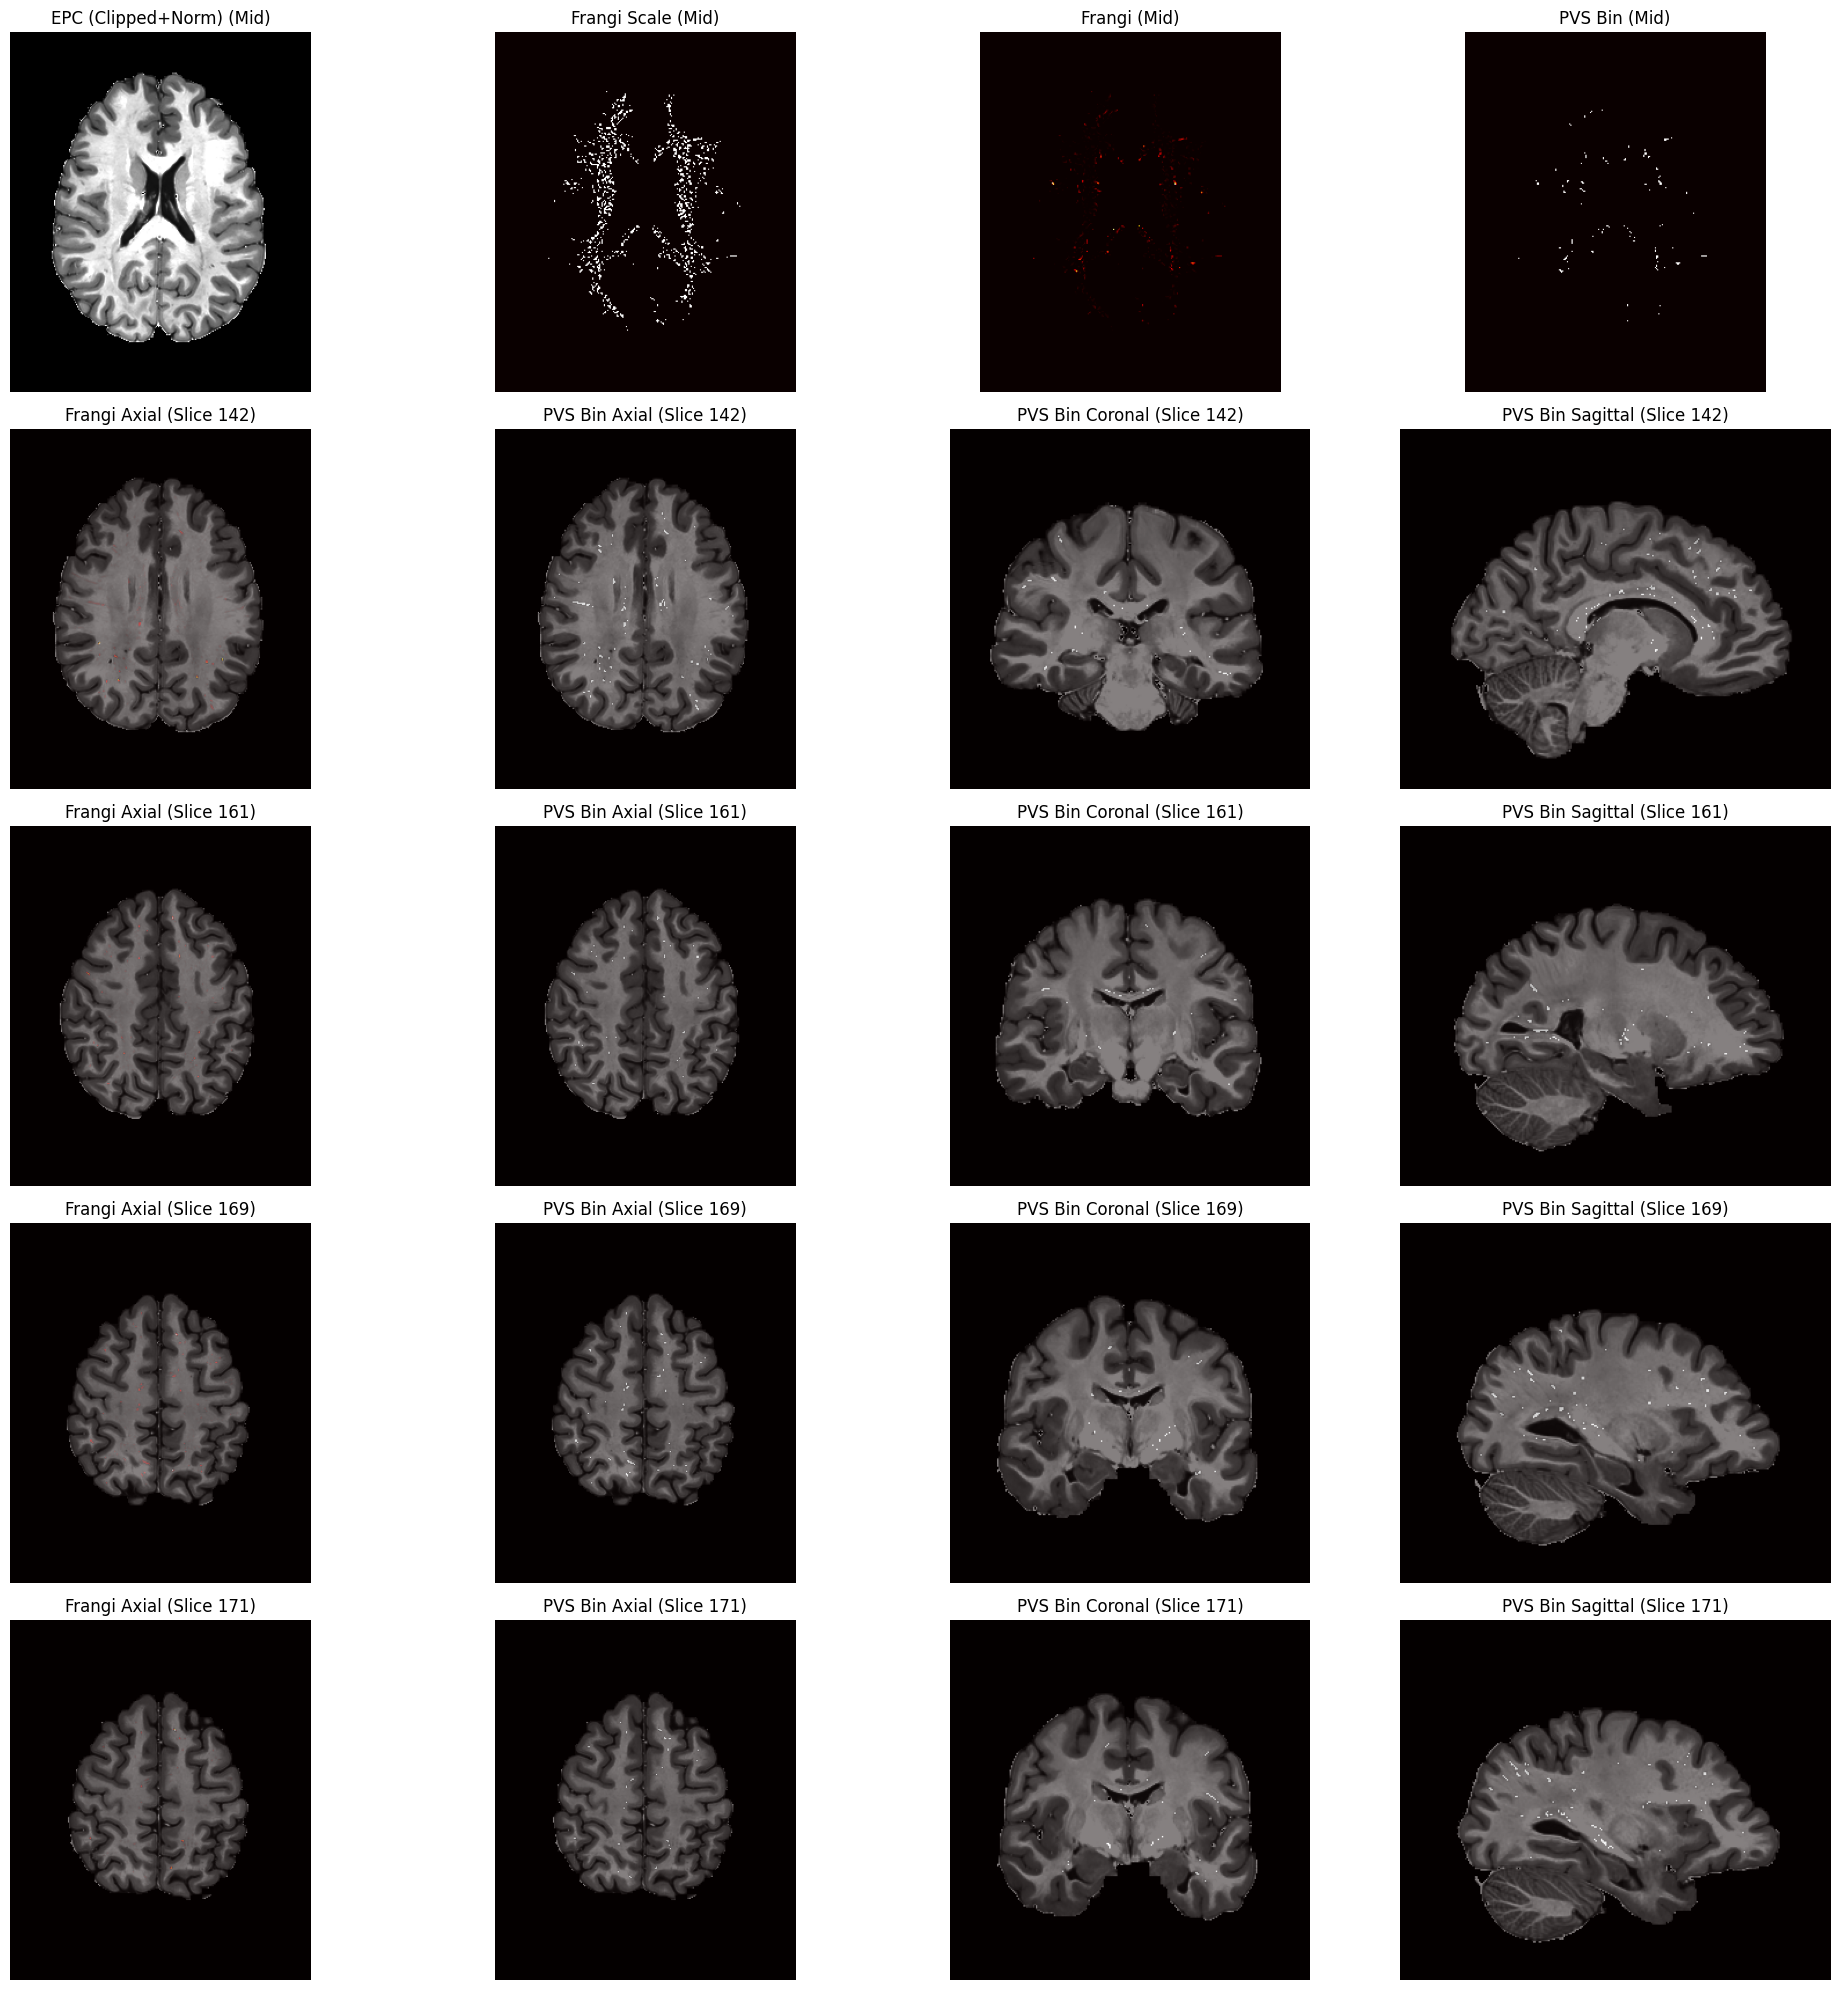

✅ Saved combined figure to results/994273/results_EPC/combined_thesis_clipped_norm.png


In [ ]:
def normalize_image(img, bias=0, scale=255, vmin=1, vmax=99):
    """Clip image between vmin/vmax percentiles, add bias, scale to [0,scale]."""
    lo, hi = np.percentile(img, [vmin, vmax])
    img = np.clip(img, lo, hi)   # cut off extreme values
    img = img + bias
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    return img * scale

def plot_subject_results_in_combined_figure(subject_id, config, modality='EPC', percentile=90):
    print(f"Selected subject: {subject_id}")

    data_path = config['paths']['data'][subject_id]
    outputs_path = config['paths']['outputs'][subject_id][f'outputs_{modality}']
    results_path = config['paths']['results'][subject_id][f'results_{modality}']
    os.makedirs(results_path, exist_ok=True)

    alpha, beta = 0.1, 0.9

    # --- Load images ---
    epc_path = os.path.join(data_path, 'EPC.nii.gz')
    frangi_path = os.path.join(outputs_path, f"frangi_{alpha}_{beta}.nii.gz")
    frangi_scale_path = os.path.join(outputs_path, f"frangi_{alpha}_{beta}.scale.nii.gz")

    # Find PVS binary mask
    pvs_bin_path = None
    for fname in os.listdir(outputs_path):
        if fname.startswith(f"pvs_bin_{alpha}_{beta}_perc{percentile}_th") and not fname.endswith("_bg.nii.gz"):
            pvs_bin_path = os.path.join(outputs_path, fname)
            break
    if pvs_bin_path is None:
        raise FileNotFoundError(f"No thresholded PVS image found with perc{percentile} in {outputs_path}.")

    # Load arrays
    epc_data = nib.load(epc_path).get_fdata()
    frangi_data = nib.load(frangi_path).get_fdata()
    frangi_scale_data = nib.load(frangi_scale_path).get_fdata()
    pvs_bin = nib.load(pvs_bin_path).get_fdata()

    # Normalize EPC for visualization with clipping
    epc_vis = normalize_image(epc_data, bias=20, vmin=1, vmax=99)

    # --- Slices ---
    slices = get_valid_slices(epc_data.shape, axis=2, requested_slices=[142, 161, 169, 171])
    mid_slice = epc_data.shape[2] // 2
    print("Slices selected for visualization:", slices)

    # --- Figure grid ---
    nrows, ncols = 1 + len(slices), 4
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    if nrows == 1:
        axes = np.expand_dims(axes, 0)

    # ------------------
    # Row 1: Mid slices
    # ------------------
    titles = ['EPC (Clipped+Norm)', 'Frangi Scale', 'Frangi', 'PVS Bin']
    images = [epc_vis, frangi_scale_data, frangi_data, pvs_bin]

    for c, (img, title) in enumerate(zip(images, titles)):
        cmap = 'gray' if c == 0 else 'hot'
        axes[0, c].imshow(np.rot90(img[:, :, mid_slice]), cmap=cmap)
        axes[0, c].set_title(f"{title} (Mid)")
        axes[0, c].axis("off")

    # ------------------
    # Rows: Overlays
    # ------------------
    for r, slc in enumerate(slices, start=1):
        # Frangi Axial
        axes[r,0].imshow(np.rot90(epc_vis[:, :, slc]), cmap="gray")
        axes[r,0].imshow(np.rot90(frangi_data[:, :, slc]), cmap="hot", alpha=0.5)
        axes[r,0].set_title(f'Frangi Axial (Slice {slc})')
        axes[r,0].axis("off")

        # PVS Bin Axial
        axes[r,1].imshow(np.rot90(epc_vis[:, :, slc]), cmap="gray")
        axes[r,1].imshow(np.rot90(pvs_bin[:, :, slc]), cmap="hot", alpha=0.5)
        axes[r,1].set_title(f'PVS Bin Axial (Slice {slc})')
        axes[r,1].axis("off")

        # PVS Bin Coronal
        axes[r,2].imshow(np.rot90(epc_vis[:, slc, :]), cmap="gray")
        axes[r,2].imshow(np.rot90(pvs_bin[:, slc, :]), cmap="hot", alpha=0.5)
        axes[r,2].set_title(f'PVS Bin Coronal (Slice {slc})')
        axes[r,2].axis("off")

        # PVS Bin Sagittal
        axes[r,3].imshow(np.rot90(epc_vis[slc, :, :]), cmap="gray")
        axes[r,3].imshow(np.rot90(pvs_bin[slc, :, :]), cmap="hot", alpha=0.5)
        axes[r,3].set_title(f'PVS Bin Sagittal (Slice {slc})')
        axes[r,3].axis("off")

    # ------------------
    plt.tight_layout()
    combined_path = os.path.join(results_path, "combined_thesis_clipped_norm.png")
    plt.savefig(combined_path, bbox_inches="tight", dpi=300)
    plt.show()

    print(f"Saved combined figure to {combined_path}")


# Example run
subject_id = '994273'
plot_subject_results_in_combined_figure(subject_id, config_all_sub)


## 3D Visualization of PVS Masks(Optional)

In [ ]:
from mayavi import mlab
# Enter the subject id and threshold
subject_id = "994273"  
threshold = 90  

# Define input file
nii_path = (
    OUTPUTS_DIR
    / subject_id
    / "outputs_EPC"
    / f"pvs_bin_perc{threshold}_after_extr_periventr_3vox.nii.gz"
)

if not nii_path.is_file():
    raise FileNotFoundError(f"File not found: {nii_path}")

# Load PVS mask
img = nib.load(str(nii_path))
data = img.get_fdata()

# Create 3D visualization
mlab.figure(
    bgcolor=(0, 0, 0),
    size=(1000, 800)
)

src = mlab.pipeline.scalar_field(data.astype(np.float32))

mlab.pipeline.iso_surface(
    src,
    contours=[0.5],
    opacity=1.0,
    color=(0, 1, 1)
)

mlab.orientation_axes()
mlab.show()
